# Why do some countries protect girls' right to education better than others?
*A machine-learning look at UNESCO's HerAtlas legal data*

## Research question

> **What factors best explain variation in national compliance with UNESCO education rights indicators across regions and time?**

## Introduction

Education is recognised as a human right in international law, but *saying* so and *writing it into national law* are two different things. HerAtlas is a UNESCO dataset that tracks whether countries' constitutions and laws actually protect girls' education, using 12 legal indicators. Examples: *Is the legal age of marriage at least 18?* *Are learners legally protected from corporal punishment?* *Is the country party to the UN women's rights convention (CEDAW)?*

Each row in the data is one country's answer to one of those questions in one year. Answers look like "Yes", "Partially" or "No", and we group them into three simple labels: **Compliant**, **Partial** and **Non-compliant**.

Here we ask: **how much of that variation can be explained by the *type of question*, the *region* of the world, and the *year*?** We use machine learning as a magnifying glass rather than a crystal ball. The goal isn't to grade countries. It's to understand which factors line up with stronger or weaker legal protection, and how far those factors get us.

**What we'll do**
1. Clean the data (and fix a few things that would quietly mislead us).
2. Explore it with charts to see the patterns by eye.
3. Train three models, plus a "do-nothing" baseline to compare against: Logistic Regression, Random Forest and a small neural network (MLP).
4. Test them fairly, using a training / validation / test split and cross-validation without data leakage.
5. Find out which factors matter most, then discuss what it means for education policy.

## About the data

The raw file has 3,582 rows and 34 columns, but most of those columns are translations of the same text (French, Arabic, Chinese...), database IDs, or map geometry. We only need a handful:

| Column (renamed) | What it is | How we use it |
|---|---|---|
| `country`, `iso3` | Country name and 3-letter code | For counting countries only; **not** a model input |
| `region` | UNESCO regional group (5 groups) | Feature |
| `year` | Year the legal framework was assessed | Feature |
| `question` | Which of the 12 legal indicators was asked | Feature |
| `on_map` | Whether the record is displayed on the HerAtlas map (an administrative flag) | Feature |
| `answer` | The recorded answer ("Yes", "Partially", "No, not explicitly", ...) | Raw version of the target |
| `label` | Compliant / Partial / Non-compliant | **Target** (what we predict) |

## 1. Setting up

We load our libraries, fix a random seed so the results are the same every time, and choose one consistent colour for each label so the charts are easy to compare. The three colours were checked to stay distinguishable for colour-blind readers.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, ParameterGrid
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42                      # same results every run
DATA_PATH = "edp002.csv"       # change this if the file lives elsewhere

# One colour per label, used in every chart
ORDER  = ["Compliant", "Partial", "Non-compliant"]
COLORS = {"Compliant": "#2a78d6", "Partial": "#1baf7a", "Non-compliant": "#eb6834"}
LABEL_INK = {"Compliant": "white", "Partial": "#0b0b0b", "Non-compliant": "#0b0b0b"}  # readable text on each colour
BAR = "#2a78d6"                # single-series charts
GREY = "#9a9a95"               # baseline / de-emphasised bars

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "font.size": 10.5, "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.max_colwidth", 80)

## 2. Loading the data



In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw[["Country Title EN", "Regional Group", "Date", "Terms", "Indicator"]].head()

Raw data: 3,582 rows x 34 columns


,Country Title EN,Regional Group,Date,Terms,Indicator
0,Afghanistan,Asia and the Pacific,2019,Does the Constitution enshrine the right to education without discrimination?,"Yes, without discrimination based on sex/gender"
1,Afghanistan,Asia and the Pacific,2019,Is equal access to post-secondary education legally guaranteed?,No
2,Afghanistan,Asia and the Pacific,2019,Is the minimum age of employment at least 15 and aligned with the end of com...,No
3,Angola,Africa,2019,Is the country party to the UN Convention on the Elimination of Discriminati...,Yes
4,Angola,Africa,2019,Does the legislation enshrine the right to education without discrimination?,Yes


## 3. Cleaning the data

There are three important steps in cleaning the data:

1. **Removing the "Header" and "Footer" rows:** These appear in the `Terms` column alongside actual policy questions. They are leftover website entries rather than real policy responses. Since they are all marked "Yes", keeping them could incorrectly increase the number of countries classified as Compliant.

2. **Removing rows with missing answers:** Rows without an answer cannot be used to train the model, so these are excluded.

3. **Grouping the 12 original answers into three categories:** The responses are grouped into Compliant, Partially Compliant and Non-Compliant. One detail matters here: "Yes, with reservations" begins with "Yes", but should not be classified as fully Compliant. To avoid this, the code checks for partial responses and reservations first, then checks for "Yes". Any remaining responses are classified as Non-Compliant.

In [3]:
# Keep only the columns we need, with friendlier names
df = raw[["Country Title EN", "iso3", "Regional Group", "Date", "Terms", "on_map", "Indicator"]].copy()
df.columns = ["country", "iso3", "region", "year", "question", "on_map", "answer"]

# 1) Remove website layout rows that are not real questions
layout_rows = df["question"].isin(["Header", "Footer"])
print(f"Header/Footer layout rows removed: {layout_rows.sum()}  (their 'answers': {df.loc[layout_rows, 'answer'].value_counts().to_dict()})")
df = df.loc[~layout_rows].copy()

# 2) Remove rows with no answer
print(f"Rows with no answer removed:        {df['answer'].isna().sum()}")
df = df.dropna(subset=["answer"]).copy()
print(f"Rows remaining:                     {len(df):,}")
print(f"Duplicate country-question-year rows: {df.duplicated(['iso3', 'question', 'year']).sum()}")

Header/Footer layout rows removed: 298  (their 'answers': {'Yes': 298})
Rows with no answer removed:        48
Rows remaining:                     3,236
Duplicate country-question-year rows: 0


In [4]:
# 3) Group raw answers into 3 labels.  ORDER MATTERS: check the in-between answers first!
def to_compliance_label(answer):
    a = answer.strip().lower()
    if "reservation" in a or "partial" in a:     # e.g. "Partially", "Yes, with reservations"
        return "Partial"
    if a.startswith("yes"):                      # e.g. "Yes", "Yes, explicitly"
        return "Compliant"
    return "Non-compliant"                       # e.g. "No", "No, not explicitly", "Corporal punishment is allowed"

df["label"] = df["answer"].apply(to_compliance_label)

# Safety checks: nothing unmapped, and "with reservations" must NOT be Compliant
assert df["label"].isin(ORDER).all()
assert (df.loc[df["answer"].str.contains("reservations", case=False), "label"] == "Partial").all()

# Show exactly how every raw answer was grouped, so the mapping can be inspected
mapping_check = (df.groupby(["label", "answer"]).size().rename("rows").reset_index())
mapping_check["label"] = pd.Categorical(mapping_check["label"], ORDER, ordered=True)
mapping_check.sort_values(["label", "rows"], ascending=[True, False]).reset_index(drop=True)

,label,answer,rows
0,Compliant,Yes,1139
1,Compliant,"Yes, without discrimination based on sex/gender",236
2,Compliant,"Yes, explicitly",90
3,Partial,Partially,705
4,Partial,"Yes, with reservations",61
5,Non-compliant,No,653
6,Non-compliant,"No, not explicitly",166
7,Non-compliant,"No, the right to education is not enshrined",145
8,Non-compliant,Corporal punishment is allowed,30
9,Non-compliant,"No, it is infringed upon",9


In [5]:
# Tidy types and give the 12 long questions short, readable names
df["on_map"] = df["on_map"].astype(int)
df["year"] = df["year"].astype(int)

SHORT_NAMES = [
    ("constitution",                    "Constitution: right to education"),
    ("legislation enshrine",            "Law: right to education"),
    ("post-secondary",                  "Equal access to post-secondary"),
    ("minimum age of employment",       "Minimum working age >= 15"),
    ("against women",                   "CEDAW ratified"),
    ("9 years",                         "9 years compulsory"),
    ("12 years",                        "12 years free"),
    ("unesco convention",               "UNESCO convention ratified"),
    ("pre-primary",                     "Pre-primary free & compulsory"),
    ("age of marriage",                 "Marriage age >= 18"),
    ("corporal punishment",             "Protection from violence"),
    ("pregnant",                        "Pregnant/parenting girls protected"),
]

def short_question(q):
    q_low = q.lower()
    for key, name in SHORT_NAMES:
        if key in q_low:
            return name
    raise ValueError(f"Unmapped question: {q}")

df["question_full"] = df["question"]
df["question"] = df["question_full"].apply(short_question)
assert df["question"].nunique() == 12

print(f"Final dataset: {len(df):,} rows | {df['iso3'].nunique()} countries | "
      f"{df['question'].nunique()} questions | {df['region'].nunique()} regions | years {df['year'].min()}-{df['year'].max()}")
df[["question", "question_full"]].drop_duplicates().sort_values("question").reset_index(drop=True)

Final dataset: 3,236 rows | 196 countries | 12 questions | 5 regions | years 2019-2025


,question,question_full
0,12 years free,Are 12 years of primary and secondary education legally free?
1,9 years compulsory,Are 9 years of primary and secondary education legally compulsory?
2,CEDAW ratified,Is the country party to the UN Convention on the Elimination of Discriminati...
3,Constitution: right to education,Does the Constitution enshrine the right to education without discrimination?
4,Equal access to post-secondary,Is equal access to post-secondary education legally guaranteed?
5,Law: right to education,Does the legislation enshrine the right to education without discrimination?
6,Marriage age >= 18,Is the legal age of marriage set at least at 18 years old?
7,Minimum working age >= 15,Is the minimum age of employment at least 15 and aligned with the end of com...
8,Pre-primary free & compulsory,Is pre-primary education legally free and compulsory?
9,Pregnant/parenting girls protected,Is pregnant and parenting girls’ right to education protected in the legal f...


## 4. Exploring the data


### 4.1 How common is each label?

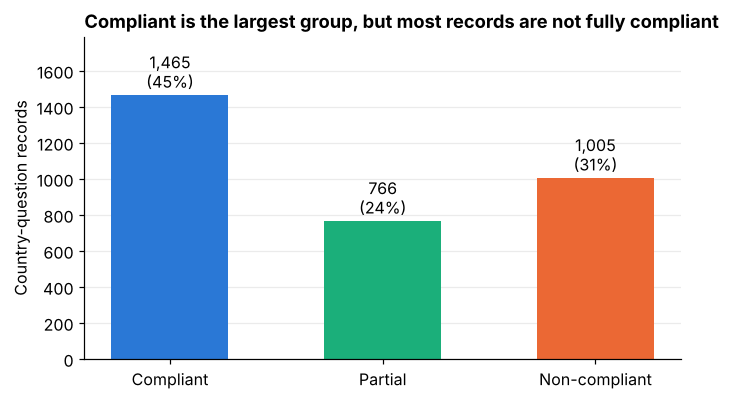

In [6]:
counts = df["label"].value_counts().reindex(ORDER)

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(ORDER, counts.values, color=[COLORS[c] for c in ORDER], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v:,}\n({v / len(df):.0%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.22)
ax.set_ylabel("Country-question records")
ax.set_title("Compliant is the largest group, but most records are not fully compliant", loc="left")
ax.grid(False, axis="x")
plt.show()

**Why this matters:** the classes are not perfectly balanced, so plain accuracy can flatter a model that just guesses the biggest class. That's why we later also report macro F1, precision and recall, which give each label equal weight, and compare everything to a baseline that always guesses the most common label.

### 4.2 Does the type of question matter?

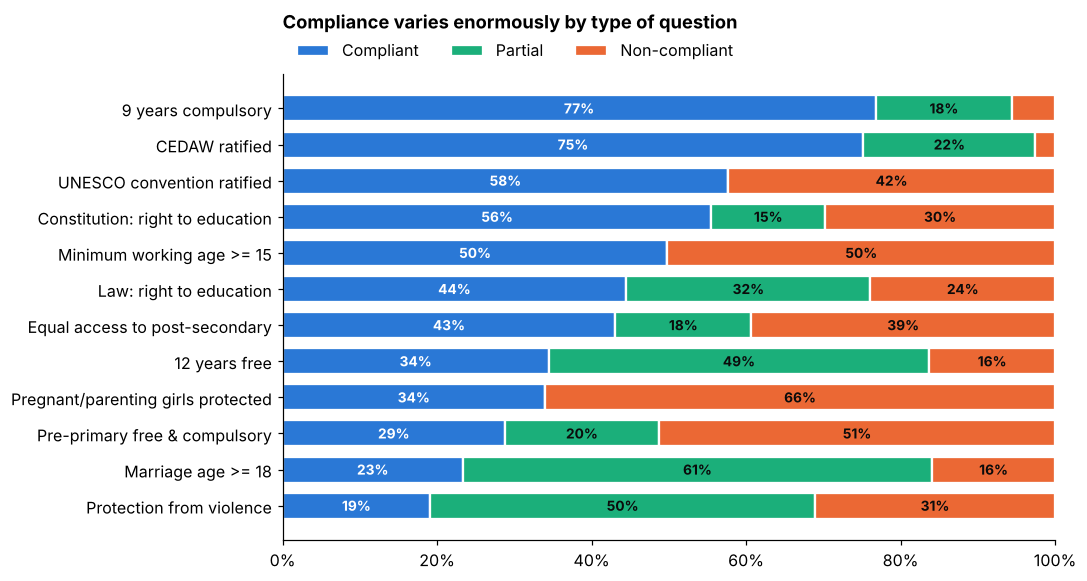

label,Compliant,Partial,Non-compliant
question,,,
9 years compulsory,76.8,17.7,5.5
CEDAW ratified,75.2,22.3,2.6
UNESCO convention ratified,57.7,0.0,42.3
Constitution: right to education,55.5,14.7,29.8
Minimum working age >= 15,49.8,0.0,50.2
Law: right to education,44.5,31.6,23.9
Equal access to post-secondary,43.1,17.6,39.3
12 years free,34.4,49.3,16.3
Pregnant/parenting girls protected,34.0,0.0,66.0


In [7]:
def pct_table(by):
    t = pd.crosstab(df[by], df["label"]).reindex(columns=ORDER, fill_value=0)
    return t.div(t.sum(axis=1), axis=0) * 100

def stacked_barh(pct, title, figsize):
    pct = pct.sort_values("Compliant", ascending=False)
    fig, ax = plt.subplots(figsize=figsize)
    left = np.zeros(len(pct))
    for c in ORDER:
        ax.barh(pct.index, pct[c], left=left, color=COLORS[c], edgecolor="white", linewidth=1.5, height=0.72, label=c)
        for y, (l, w) in enumerate(zip(left, pct[c])):
            if w >= 7:
                ax.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center", color=LABEL_INK[c], fontsize=9, fontweight="bold")
        left += pct[c].values
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.invert_yaxis()
    ax.grid(False)
    ax.set_title(title, loc="left", pad=30)
    ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
    plt.tight_layout()
    plt.show()

pct_question = pct_table("question")
stacked_barh(pct_question, "Compliance varies enormously by type of question", (10, 5.4))
pct_question.sort_values("Compliant", ascending=False).round(1)

### 4.3 Does the region matter?

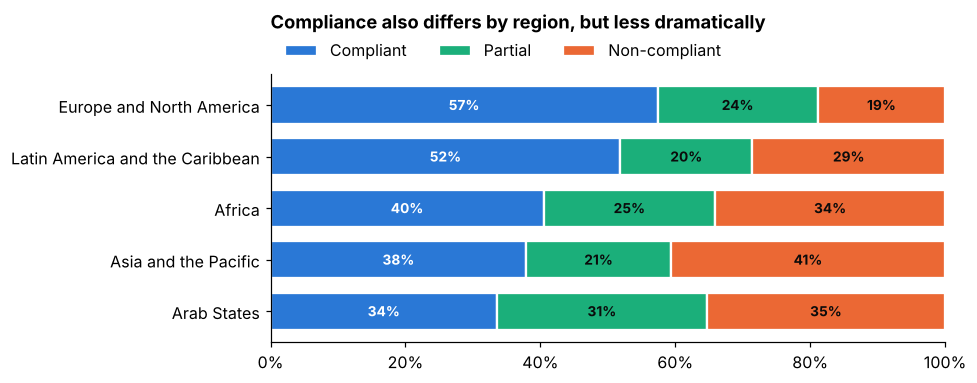

label,Compliant,Partial,Non-compliant
region,,,
Europe and North America,57.4,23.8,18.9
Latin America and the Caribbean,51.8,19.6,28.6
Africa,40.5,25.4,34.1
Asia and the Pacific,37.9,21.4,40.7
Arab States,33.6,31.1,35.3


In [8]:
pct_region = pct_table("region")
stacked_barh(pct_region, "Compliance also differs by region, but less dramatically", (9, 3.6))
pct_region.sort_values("Compliant", ascending=False).round(1)

### 4.4 Region and question together

This heatmap shows the percentage of Compliant responses for each question across different regions. Darker blue indicates a higher share of Compliant responses. Looking at regions and questions together helps identify whether countries in different parts of the world show similar or different levels of compliance on the same issues.

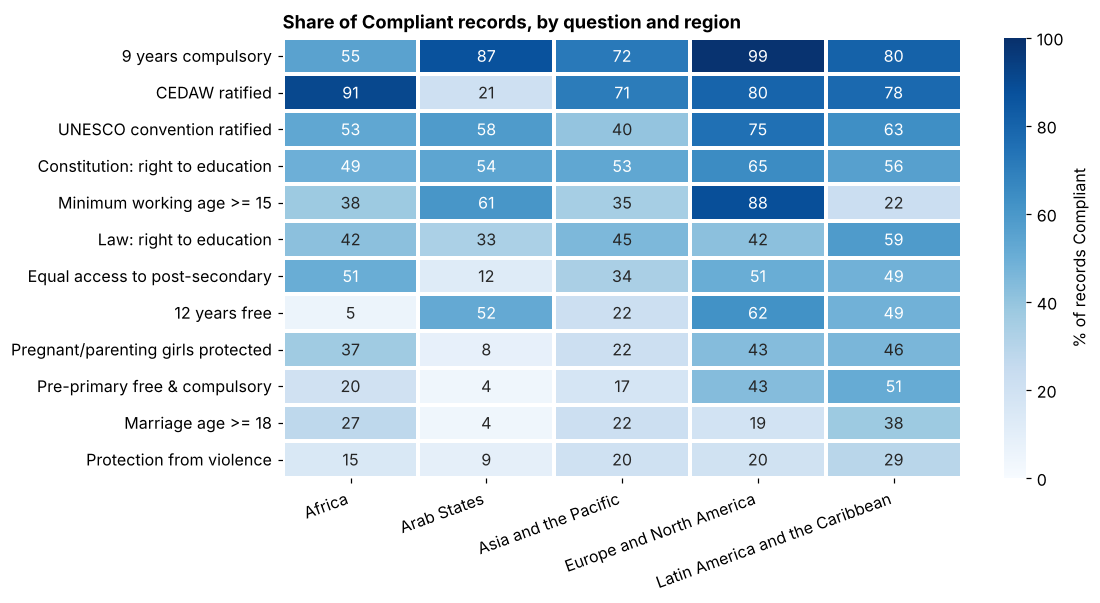

In [9]:
heat = (df.assign(is_compliant=(df["label"] == "Compliant"))
          .pivot_table(index="question", columns="region", values="is_compliant", aggfunc="mean") * 100)
heat = heat.loc[pct_question.sort_values("Compliant", ascending=False).index]

fig, ax = plt.subplots(figsize=(10.5, 5.6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            linewidths=1.5, linecolor="white", cbar_kws={"label": "% of records Compliant"}, ax=ax)
ax.set_title("Share of Compliant records, by question and region", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 4.5 What about time?



,records,countries,pct_compliant
year,,,
2019,2316,196,41.8
2020,144,12,56.2
2021,166,14,55.4
2022,281,24,52.3
2023,165,14,57.0
2024,105,9,48.6
2025,59,5,55.9


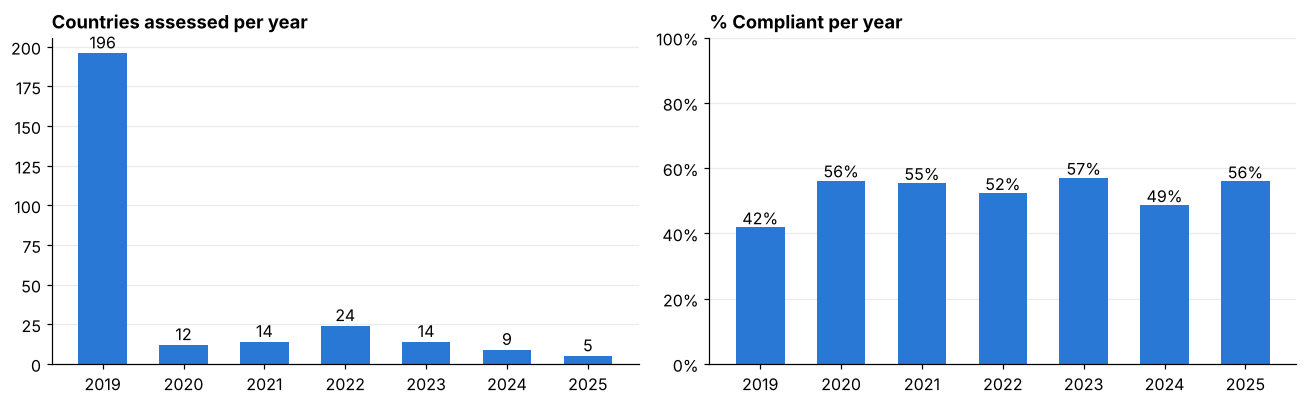

In [10]:
by_year = df.groupby("year").agg(records=("label", "size"),
                                 countries=("iso3", "nunique"),
                                 pct_compliant=("label", lambda s: (s == "Compliant").mean() * 100)).round(1)
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
years = by_year.index.astype(str)

axes[0].bar(years, by_year["countries"], color=BAR, width=0.6)
for x, v in zip(years, by_year["countries"]):
    axes[0].text(x, v + 3, str(v), ha="center")
axes[0].set_title("Countries assessed per year", loc="left")
axes[0].grid(False, axis="x")

axes[1].bar(years, by_year["pct_compliant"], color=BAR, width=0.6)
for x, v in zip(years, by_year["pct_compliant"]):
    axes[1].text(x, v + 1, f"{v:.0f}%", ha="center")
axes[1].set_ylim(0, 100)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_title("% Compliant per year", loc="left")
axes[1].grid(False, axis="x")

plt.tight_layout()
plt.show()

**An honest note about time:** almost all countries were assessed in **2019** (the baseline). The later years only cover a small number of countries that were re-assessed, so they are not a clean before/after trend across the world. Differences between years partly reflect which countries were re-assessed, so we should be careful not to read them as "the world is getting better or worse".

### 4.6 How strongly is each factor linked to the label?

Cramér's V is a measure of association between two categorical variables. It ranges from 0 (no link) to 1 (perfectly linked). It's a better fit here than a classic correlation heatmap, because our variables are categories, not numbers.

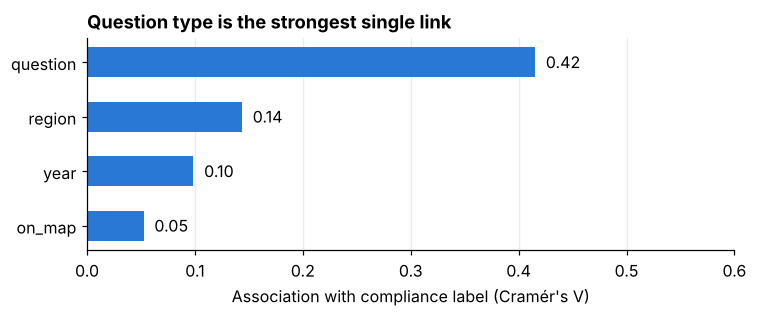

In [11]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt((chi2 / n) / (min(table.shape) - 1))

assoc = pd.Series({
    "question": cramers_v(df["question"], df["label"]),
    "region":   cramers_v(df["region"], df["label"]),
    "year":     cramers_v(df["year"].astype(str), df["label"]),
    "on_map":   cramers_v(df["on_map"].astype(str), df["label"]),
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(assoc.index, assoc.values, color=BAR, height=0.55)
for y, v in enumerate(assoc.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center")
ax.set_xlim(0, max(0.6, assoc.max() * 1.2))
ax.set_xlabel("Association with compliance label (Cramér's V)")
ax.set_title("Question type is the strongest single link", loc="left")
ax.grid(False, axis="y")
plt.tight_layout()
plt.show()

## 5. Preparing for modelling

### 5.1 Features and the three-way split

We use four features: `question`, `region`, `year` and `on_map`. The target is `label`.

Instead of a single train/test split, we split the data **three ways**:

- **Train (60%)**: the models learn from this.
- **Validation (20%)**: we use this to compare models and choose their settings.
- **Test (20%)**: locked away until the very end, used **once** for the final scores.

If we picked settings by looking at the test set, it would quietly become part of training and our final scores would be too optimistic. Each split keeps the same label proportions (*stratified*).

In [12]:
FEATURES = ["question", "region", "year", "on_map"]
X = df[FEATURES]
y = df["label"]

# Step 1: lock away 20% as the final test set
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
# Step 2: split the remaining 80% into train (60% overall) and validation (20% overall)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} {len(part):>5,} rows  ({len(part) / len(y):.0%})")

Train       1,941 rows  (60%)
Validation    647 rows  (20%)
Test          648 rows  (20%)


### 5.2 Preprocessing inside a Pipeline

Models work with numbers rather than text, so we first convert the categorical variables (`question` and `region`) into numerical columns using **one-hot encoding**. We also standardise `year` so that it is on a common scale with the other numerical inputs.

An important part of this process is making sure the model does not get access to information from the data it is supposed to be tested on. To do this, we combine the preprocessing steps and the model in a scikit-learn **Pipeline**. This ensures that the encoder and scaler are fitted only on the training data in each split, including during cross-validation. If we scaled the entire dataset before cross-validation, information from the held-out data could leak into the training process and affect the results.

In [13]:
def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["question", "region"]),   # text -> 0/1 columns
        ("num", StandardScaler(), ["year"]),                                       # scale the year
        ("bin", "passthrough", ["on_map"]),                                        # already 0/1
    ])

def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

## 6. The models (and a baseline)

We train three different *kinds* of model, plus a baseline, so we can see whether the extra complexity buys us anything:

- **Baseline**: always predicts the most common label. If a model can't beat this, it has learned nothing useful.
- **Logistic Regression**: a simple, transparent model that adds up the evidence from each feature. It's our starting point, and it's easy to explain to a non-technical audience.
- **Random Forest**: hundreds of decision trees that vote together. It can pick up combinations (like "this question *in this region*") that a linear model can't.
- **Neural network (MLP)**: a small network with two layers of artificial "neurons" (scikit-learn's `MLPClassifier`). It's the most flexible of the three and tests whether more complex pattern-finding helps.

**How we score them.** *Accuracy* is the share of correct predictions. *Precision* asks: of the records predicted as a label, how many really were? *Recall* asks: of the records that really had a label, how many did we find? *F1* balances the two. We report the **macro** average, which treats all three labels equally so the smaller *Partial* group isn't ignored.

In [14]:
def scores(y_true, y_pred):
    return {
        "Accuracy":          accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)":        f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

baseline = make_pipeline(DummyClassifier(strategy="most_frequent"))

# Each candidate = (pipeline, a small grid of settings to try on the validation set)
candidates = {
    "Logistic Regression": (
        make_pipeline(LogisticRegression(max_iter=2000)),
        {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (
        make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
        {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [1, 5, 10]}),
    "Neural Network (MLP)": (
        make_pipeline(MLPClassifier(early_stopping=True, max_iter=500, random_state=SEED)),
        {"model__hidden_layer_sizes": [(32,), (64, 32)], "model__alpha": [1e-4, 1e-2]}),
}

## 7. Choosing settings on the validation set

We try a few combinations, train on the **train** set, and keep whichever scores best on the **validation** set. The test set stays untouched.

In [15]:
best_params = {}
for name, (pipe, grid) in candidates.items():
    best_f1, best_setting = -1, None
    for params in ParameterGrid(grid):
        fitted = clone(pipe).set_params(**params).fit(X_train, y_train)
        f1 = f1_score(y_val, fitted.predict(X_val), average="macro")
        if f1 > best_f1:
            best_f1, best_setting = f1, params
    best_params[name] = best_setting
    pretty = {k.replace("model__", ""): v for k, v in best_setting.items()}
    print(f"{name:<22} best settings: {pretty}  ->  validation macro-F1 = {best_f1:.3f}")

Logistic Regression    best settings: {'C': 1}  ->  validation macro-F1 = 0.585


Random Forest          best settings: {'max_depth': None, 'min_samples_leaf': 10}  ->  validation macro-F1 = 0.593


Neural Network (MLP)   best settings: {'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}  ->  validation macro-F1 = 0.583


In [16]:
# Validation scores of each model (trained on the train set only) next to the baseline
val_rows = {"Baseline": scores(y_val, clone(baseline).fit(X_train, y_train).predict(X_val))}
for name, (pipe, _) in candidates.items():
    fitted = clone(pipe).set_params(**best_params[name]).fit(X_train, y_train)
    val_rows[name] = scores(y_val, fitted.predict(X_val))

pd.DataFrame(val_rows).T.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Baseline,0.453,0.151,0.333,0.208
Logistic Regression,0.594,0.586,0.585,0.585
Random Forest,0.607,0.602,0.588,0.593
Neural Network (MLP),0.595,0.588,0.580,0.583


## 8. Are the results stable? Cross-validation

One train-validation split might just be lucky, or it might give us an unusually bad result. To make sure our model performs consistently, we also use 5-fold cross-validation on the combined training and validation data, while keeping the test set untouched.

Basically, we divide the data into five parts. Each time, the model trains on four parts and is evaluated on the remaining one. We repeat this until every part has had its turn. Since our preprocessing steps are included in the Pipeline, each round also fits its own encoder and scaler using only that round's training data. This prevents data leakage and ensures a fair evaluation.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
to_cv = {"Baseline": clone(baseline)}
for name, (pipe, _) in candidates.items():
    to_cv[name] = clone(pipe).set_params(**best_params[name])

cv_rows = {}
for name, pipe in to_cv.items():
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    cv_rows[name] = {
        "Accuracy (mean +/- sd)":   f"{res['test_accuracy'].mean():.3f} +/- {res['test_accuracy'].std():.3f}",
        "F1 macro (mean +/- sd)":   f"{res['test_f1_macro'].mean():.3f} +/- {res['test_f1_macro'].std():.3f}",
    }
pd.DataFrame(cv_rows).T

,Accuracy (mean +/- sd),F1 macro (mean +/- sd)
Baseline,0.453 +/- 0.001,0.208 +/- 0.000
Logistic Regression,0.592 +/- 0.016,0.579 +/- 0.016
Random Forest,0.603 +/- 0.015,0.581 +/- 0.017
Neural Network (MLP),0.594 +/- 0.017,0.563 +/- 0.034


A small spread (the number after the "+/-") means the scores don't depend much on which rows happened to land in which fold. Note that this is a stability check, not the final grade. 

## 9. Final results on the test set

We retrain each model with its chosen settings on all the train + validation data, and score it **once** on the test set it has never seen.

In [18]:
final_models = {"Baseline": clone(baseline).fit(X_dev, y_dev)}
for name, (pipe, _) in candidates.items():
    final_models[name] = clone(pipe).set_params(**best_params[name]).fit(X_dev, y_dev)

test_preds = {name: m.predict(X_test) for name, m in final_models.items()}
test_table = pd.DataFrame({name: scores(y_test, p) for name, p in test_preds.items()}).T.round(3)
test_table

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Baseline,0.452,0.151,0.333,0.208
Logistic Regression,0.593,0.581,0.583,0.582
Random Forest,0.625,0.614,0.608,0.610
Neural Network (MLP),0.617,0.604,0.604,0.604


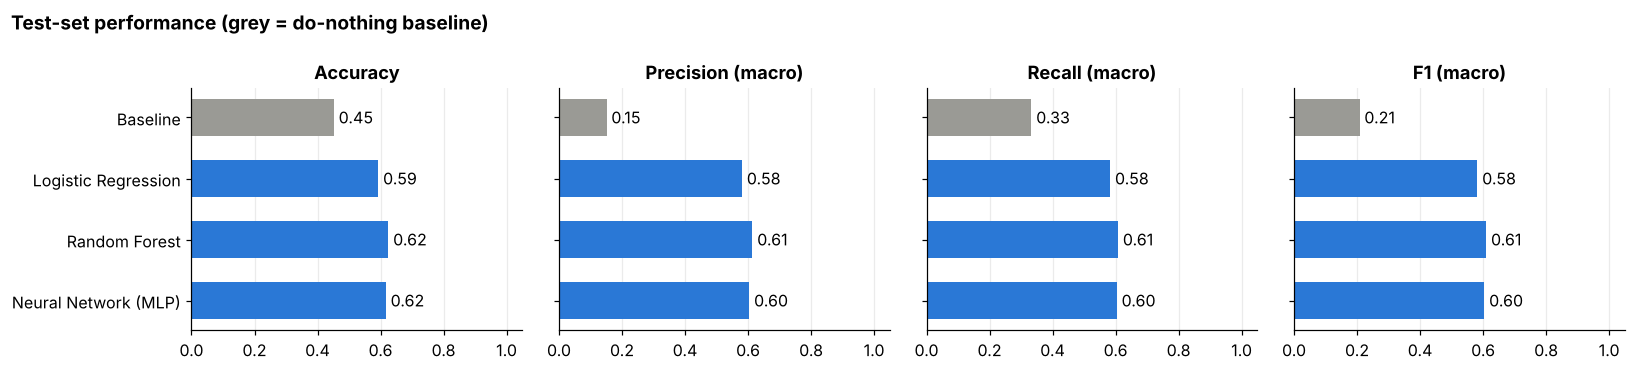

In [19]:
metrics = list(test_table.columns)
names = test_table.index.tolist()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, metric in zip(axes, metrics):
    vals = test_table[metric]
    ax.barh(names, vals, color=[GREY if n == "Baseline" else BAR for n in names], height=0.6)
    for y_pos, v in enumerate(vals):
        ax.text(v + 0.015, y_pos, f"{v:.2f}", va="center")
    ax.set_xlim(0, 1.05)
    ax.set_title(metric)
    ax.grid(False, axis="y")
axes[0].invert_yaxis()
plt.suptitle("Test-set performance (grey = do-nothing baseline)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### Where do the models go wrong?

A confusion matrix shows, for each *true* label (rows), how often the model predicted each label (columns). Each row adds up to 100%, so the diagonal shows **recall**: how many of that label the model found.

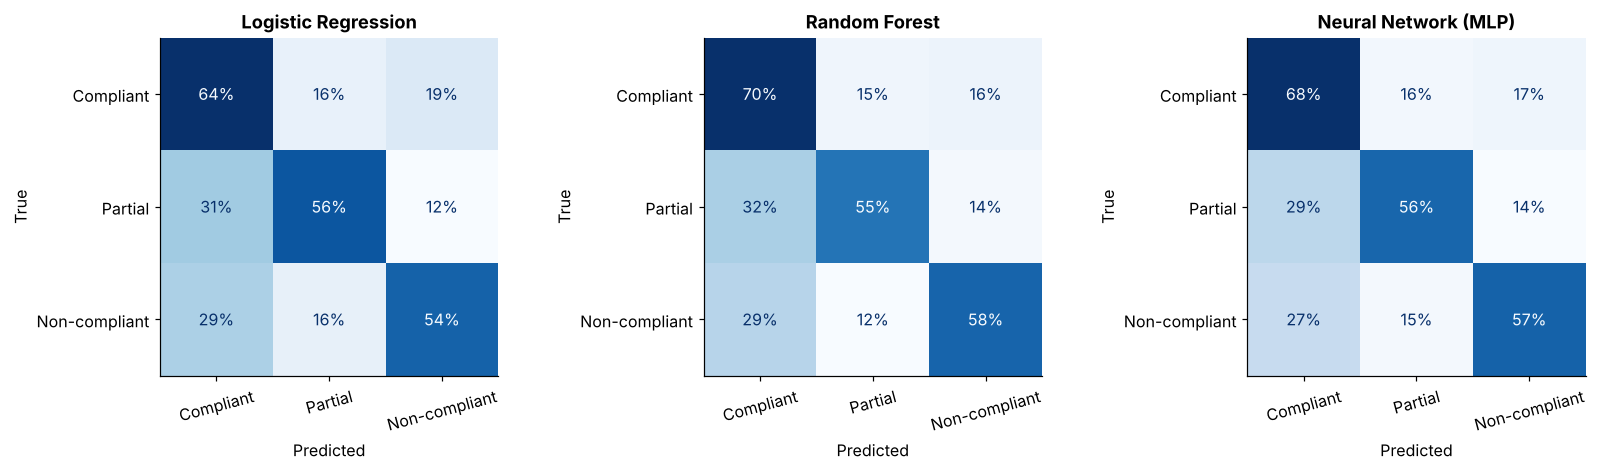

In [20]:
model_names = [n for n in final_models if n != "Baseline"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, name in zip(axes, model_names):
    ConfusionMatrixDisplay.from_predictions(y_test, test_preds[name], labels=ORDER, normalize="true",
                                            cmap="Blues", values_format=".0%", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.grid(False)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [21]:
best_name = test_table.drop(index="Baseline")["F1 (macro)"].idxmax()
print(f"Best model by macro-F1 on the test set: {best_name}\n")
print(classification_report(y_test, test_preds[best_name], labels=ORDER, zero_division=0))

Best model by macro-F1 on the test set: Random Forest

               precision    recall  f1-score   support

    Compliant       0.65      0.70      0.67       293
      Partial       0.55      0.55      0.55       154
Non-compliant       0.64      0.58      0.61       201

     accuracy                           0.62       648
    macro avg       0.61      0.61      0.61       648
 weighted avg       0.62      0.62      0.62       648



## 10. What drives compliance? Feature importance

This is the part that answers our research question. We use **permutation importance**: shuffle one factor at a time and see how much the model's macro-F1 drops. A big drop means the model leaned heavily on that factor; a drop near zero means it barely mattered.

We run it on both the Random Forest and the Logistic Regression. If two very different models agree on what matters, we can trust the finding more.

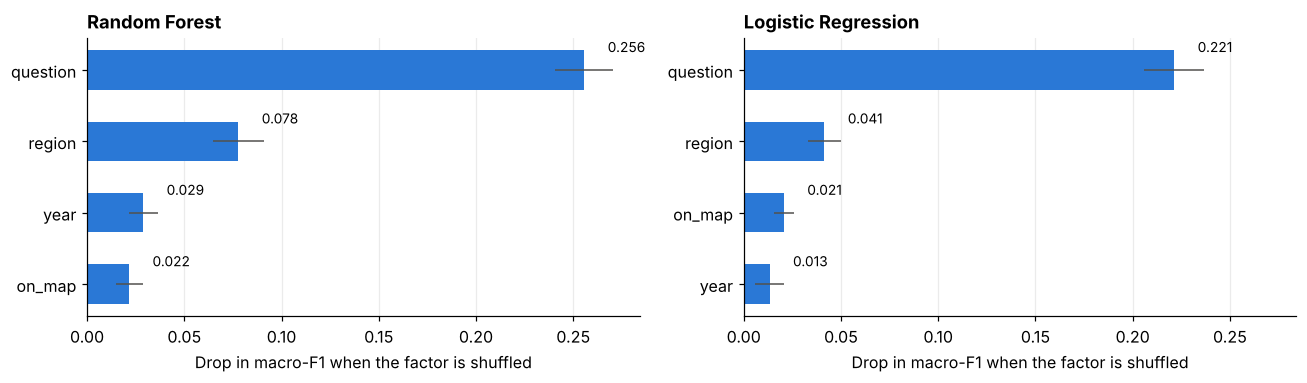

,Random Forest,Logistic Regression
question,0.256,0.221
region,0.078,0.041
year,0.029,0.013
on_map,0.022,0.021


In [22]:
def permutation_table(model):
    r = permutation_importance(model, X_test, y_test, scoring="f1_macro", n_repeats=30,
                               random_state=SEED, n_jobs=-1)
    return pd.DataFrame({"importance": r.importances_mean, "sd": r.importances_std}, index=X_test.columns)

perm = {name: permutation_table(final_models[name]) for name in ["Random Forest", "Logistic Regression"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for ax, (name, tbl) in zip(axes, perm.items()):
    tbl = tbl.sort_values("importance")
    ax.barh(tbl.index, tbl["importance"], xerr=tbl["sd"], color=BAR, height=0.55,
            error_kw={"ecolor": "#52514e", "elinewidth": 1})
    for y_pos, v in enumerate(tbl["importance"]):
        ax.text(max(v, 0) + 0.012, y_pos + 0.32, f"{v:.3f}", va="center", fontsize=9)
    ax.set_title(name, loc="left")
    ax.set_xlabel("Drop in macro-F1 when the factor is shuffled")
    ax.grid(False, axis="y")
plt.tight_layout()
plt.show()

pd.concat({k: v["importance"].round(3) for k, v in perm.items()}, axis=1).sort_values("Random Forest", ascending=False)

Permutation importance tells us *which factor* matters. To see *which specific categories* the Random Forest relies on, here are its top 12 individual features.

**A caution when reading this one:** this type of importance (built into Random Forests) is known to favour numeric features with many possible values, like `year`. That's why `year` looks bigger here than in the permutation chart above. So use this chart to compare *categories* (which questions and regions stand out), and use the permutation chart to compare *factors*.

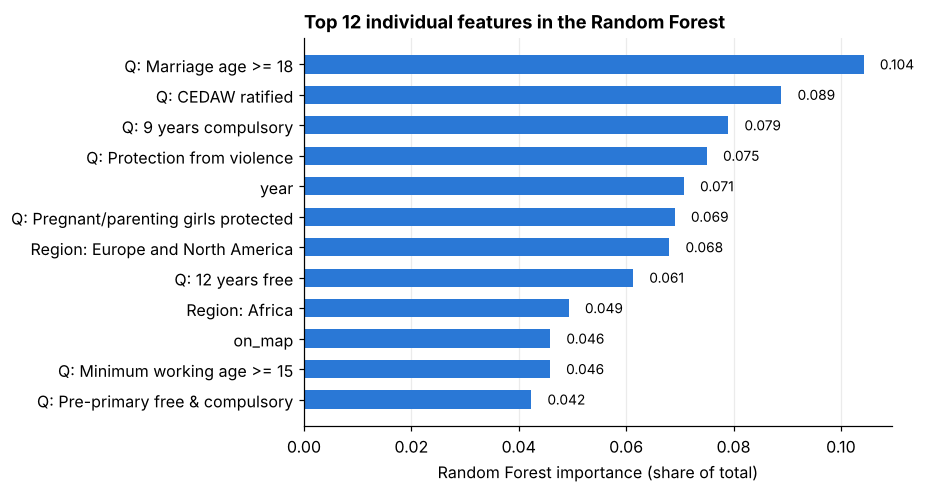

In [23]:
rf = final_models["Random Forest"]
feature_names = rf.named_steps["prep"].get_feature_names_out()
gini = (pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names)
          .sort_values(ascending=False).head(12))
gini.index = [n.split("__", 1)[1].replace("question_", "Q: ").replace("region_", "Region: ") for n in gini.index]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(gini.index[::-1], gini.values[::-1], color=BAR, height=0.6)
for y_pos, v in enumerate(gini.values[::-1]):
    ax.text(v + 0.003, y_pos, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Random Forest importance (share of total)")
ax.set_title("Top 12 individual features in the Random Forest", loc="left")
ax.grid(False, axis="y")
plt.tight_layout()
plt.show()

## 11. Conclusion: what this means for education policy


### Answering the research question

**Which factors best explain variation in compliance? The type of legal question matters most by a wide margin, then region, and year only weakly.**

| Factor | Permutation importance, Random Forest | Permutation importance, Logistic Regression | Cramér's V with label |
|---|---|---|---|
| `question` | 0.256 | 0.221 | 0.42 |
| `region` | 0.078 | 0.041 | 0.14 |
| `year` | 0.029 | 0.013 | 0.10 |
| `on_map` | 0.022 | 0.021 | 0.05 |

Three different ways of measuring, using two very different models, tell the same story, which makes us more confident in it. 

### How well did the models do?

| Model (test set) | Accuracy | Macro F1 |
|---|---|---|
| Baseline (always guess the most common label) | 0.452 | 0.208 |
| Logistic Regression | 0.593 | 0.582 |
| Random Forest | 0.625 | 0.610 |
| Neural network (MLP) | 0.617 | 0.604 |

All three models perform better than the baseline, correctly predicting around 6 out of every 10 records. However, their results are quite close to each other. The difference between them is about the same as the variation we saw across cross-validation folds (around 0.02), so we cannot confidently say that one model is better than the others.

Interestingly, Logistic Regression, which is the simplest and easiest to explain, performs almost as well as the neural network. This suggests that the patterns in our data may not be particularly complex.

The hardest category to predict is Partial. For the Random Forest model, its F1 score is 0.55, compared to 0.67 for Compliant and 0.61 for Non-compliant. This is understandable because Partial sits somewhere between the other two categories, making it harder for the model to distinguish.

### What the patterns say about policy

- **Compliance gaps are concentrated in specific policy areas**. Countries perform best on 9 years of compulsory schooling (77% compliant) and CEDAW ratification (75%). However, compliance is much lower for protection from violence and corporal punishment (19%), a minimum marriage age of 18 (23%), free pre-primary education (29%), and protection for pregnant and parenting girls (34%). In simple terms, countries seem more likely to commit to broad principles and international agreements than to put specific protections in place that directly affect girls' everyday lives. The data shows this gap, although it cannot explain why it exists.

- **Many countries have only partially met their commitments**. For minimum marriage age (61%), protection from violence (50%), and 12 years of free education (49%), Partial is the most common category. This means many countries have already taken some steps but have not fully met the requirements. These areas could be important starting points for targeted policy changes that help move countries towards full compliance.

- **Regional differences depend on the policy area**. Overall, Europe and North America have the highest compliance (57%), while the Arab States have the lowest (34%). However, the regional heatmap shows that this pattern changes depending on the issue. For example, CEDAW ratification is 91% in Africa but only 21% in the Arab States. Meanwhile, compliance with 12 years of free education is just 5% in Africa, compared to 62% in Europe and North America. This shows why we should not rely on one overall regional ranking. Policy priorities need to consider both the region and the specific issue.

### Limitations (what this analysis can't tell us)

- **There is still a lot the models cannot explain**. Around 4 in 10 predictions are incorrect. This is partly because the models only know the policy question, region and year. They do not have information about a country's income, political situation, legal system or history, all of which could influence its level of compliance.

- **Some of the question effect comes from how the survey is designed**. Not every question has the same possible answers. For example, three questions (UNESCO convention, minimum working age, and protection for pregnant and parenting girls) never use the Partial category. This means some of the relationship between the question and the predicted category is already built into the way the data was collected.

- **There is limited information across time**. Almost all countries were assessed in 2019. The later years include only 5 to 24 countries each, which is not enough to identify a reliable global trend over time.

- **Having a law does not mean it is enforced**. The dataset tells us what legal protections countries have on paper, but not whether those laws are actually implemented or whether girls benefit from them in practice. Similarly, the relationships we identify are associations, not proof that one factor causes another.

- **Small differences between models should be interpreted carefully**. The test set contains 648 records, so performance differences of 0.02 to 0.03 may simply be due to random variation rather than a meaningful improvement. Also, the same country appears in multiple rows. Although country identity is not used as a model feature, records from the same country may still be related, meaning the observations are not completely independent.

### Possible next steps

Add country-level information (income, conflict, legal system) to see how much of the unexplained 40% it accounts for; split the data by *country* rather than by row for an even stricter test; and revisit the time question as more countries are re-assessed after the 2019 baseline.